# 11 · Continuous noise and counterfactuals

A continuous mechanism with a neural location and non-Gaussian noise.  We fit an
MLP location with a Gaussian-mixture noise, compare it with Gaussian noise on
held-out data, check that one noise law fits every dose (sharing test), bound
`P(a < level <= b | dose)` with a DKW band, and answer a counterfactual
question for observed patients.

- **NBN API:** `nbn.scm.StructuralCausalModel`, `AdditiveNoiseMechanism`,
  `noise_sharing_test`, `cdf_band_set`, `counterfactual_sample`.
- **Runtime:** under 10 s on a laptop CPU.
- **Install:** `pip install "nbn[examples]"`, then `jupyter lab examples/`.
- **Device:** CUDA or Apple MPS when available, else the CPU (set `NBN_EXAMPLES_DEVICE=cpu` to force the CPU).

Ground truth:

    dose  ~ N(0, 1)
    level = sin(2 * dose) + U,   U = +-0.8 with prob 1/2 each, plus N(0, 0.2^2)

The noise is bimodal, so a Gaussian is the wrong law.

In [1]:
import os

import matplotlib.pyplot as plt
import torch

from nbn.scm import AdditiveNoiseMechanism, StructuralCausalModel, cdf_band_set, noise_sharing_test
from nbn.utils.device import resolve_device
from _figures import BLUE, ORANGE, AQUA, GREY, INK, DOUBLE, SINGLE, save, use_style

use_style()  # one style for every example: palette, sizes, fonts (_figures.py)

# "auto" picks CUDA, then Apple MPS, then the CPU.  The stored outputs were made
# with NBN_EXAMPLES_DEVICE=cpu; on an accelerator the last digits can differ.
device = resolve_device(os.environ.get("NBN_EXAMPLES_DEVICE", "auto"))
print("device:", device)



def to_numpy(t: torch.Tensor):
    """Move to the CPU first, then convert: tensors on MPS / CUDA cannot go to numpy directly."""
    return t.detach().cpu().numpy()

device: cpu


## The data

6000 training rows and 3000 held-out rows.

In [2]:
torch.manual_seed(0)


def simulate(n: int) -> dict:
    dose = torch.randn(n, 1)
    bimodal = torch.where(torch.rand(n, 1) < 0.5, -0.8, 0.8) + 0.2 * torch.randn(n, 1)
    return {"dose": dose, "level": torch.sin(2 * dose) + bimodal}


train, held_out = simulate(6000), simulate(3000)

## 1. Gaussian noise vs mixture noise

Two models with the same MLP location `g(dose)`; only the noise law differs.
The held-out log-likelihood tells which noise fits.

In [3]:
def scm(noise: str) -> StructuralCausalModel:
    model = StructuralCausalModel([("dose", "level")],
                                  {"dose": ("continuous", 1), "level": ("continuous", 1)},
                                  device=device)
    model.set_mechanism("dose", AdditiveNoiseMechanism("linear"))
    model.set_mechanism("level", AdditiveNoiseMechanism("mlp", noise, n_components=2,
                                                         epochs=150, batch_size=512))
    model.fit(train)
    return model


gaussian, mixture = scm("gaussian"), scm("mixture")
for name, model in (("gaussian noise", gaussian), ("mixture noise ", mixture)):
    print(f"{name}: held-out mean log-likelihood {model.log_prob(held_out).mean():.3f}")

noise = mixture.mechanisms["level"].noise
print("fitted mixture: weights", [round(w, 2) for w in noise.mix_logits.softmax(-1).tolist()],
      " means", [round(m, 2) for m in noise.means.squeeze(-1).tolist()])

gaussian noise: held-out mean log-likelihood -2.646
mixture noise : held-out mean log-likelihood -1.966
fitted mixture: weights [0.49, 0.51]  means [-0.79, 0.82]


Left: the held-out data, the true location `sin(2 dose)` and the fitted MLP
location.  Right: the held-out residuals `level - g(dose)` with the two fitted
noise densities.  The mixture finds both modes; the Gaussian puts its mass
between them, where there is little data.

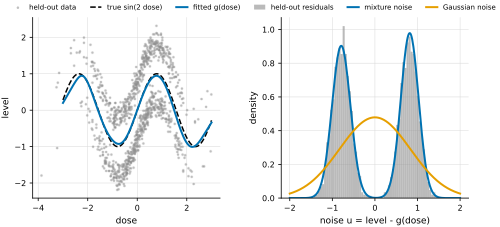

In [4]:
level_mech = mixture.mechanisms["level"]
grid = torch.linspace(-3, 3, 200).unsqueeze(-1)
with torch.no_grad():
    fitted_g = level_mech.location(grid.to(device))
    resid = level_mech.residual(held_out["level"].to(device), held_out["dose"].to(device))
    u = torch.linspace(-2, 2, 300).unsqueeze(-1).to(device)
    zero = torch.zeros_like(u)
    dens_mix = noise.distribution(zero).log_prob(u).exp()
    dens_gauss = gaussian.mechanisms["level"].noise.distribution(zero).log_prob(u).exp()

fig, (ax_g, ax_u) = plt.subplots(1, 2, figsize=(DOUBLE, 3.2))
ax_g.scatter(to_numpy(held_out["dose"][:1000]), to_numpy(held_out["level"][:1000]), s=4,
             color=GREY, alpha=0.5, label="held-out data", rasterized=True)
ax_g.plot(to_numpy(grid), to_numpy(torch.sin(2 * grid)), color=INK, lw=1.5, ls="--",
          label="true sin(2 dose)")
ax_g.plot(to_numpy(grid), to_numpy(fitted_g), color=BLUE, lw=2, label="fitted g(dose)")
ax_g.set(xlabel="dose", ylabel="level")
ax_g.legend(frameon=False, fontsize=7, loc="lower center", bbox_to_anchor=(0.5, 1.0), ncol=3)
ax_u.hist(to_numpy(resid).reshape(-1), bins=60, density=True, color=GREY, alpha=0.6,
          label="held-out residuals")
ax_u.plot(to_numpy(u), to_numpy(dens_mix), color=BLUE, lw=2, label="mixture noise")
ax_u.plot(to_numpy(u), to_numpy(dens_gauss), color=ORANGE, lw=2, label="Gaussian noise")
ax_u.set(xlabel="noise u = level - g(dose)", ylabel="density")
ax_u.legend(frameon=False, fontsize=7, loc="lower center", bbox_to_anchor=(0.5, 1.0), ncol=3)
save(fig, "11_fig1")      # vector PDF + 300-dpi PNG in examples/figures/
plt.show()

**Figure.** Left: held-out rows, the true location `sin(2 dose)` (dashed) and the fitted location `g(dose)`. Right: histogram of the held-out residuals `level - g(dose)`, with the fitted mixture noise law and a fitted Gaussian.

## 2. One noise law for every dose?

`noise_sharing_test` regresses the scale of the residuals on `dose` and
`dose^2`.

In [5]:
sharing = noise_sharing_test(mixture, held_out, "level")
verdict = ("rejected: the noise scale changes with the dose" if sharing.rejected(0.01)
           else "not rejected at the 1% level")
print(f"sharing test: p = {sharing.p_value:.3f} -> {verdict}")
print("  (a small p here can also come from MLP misfit: residual error that varies with the dose)")

sharing test: p = 0.048 -> not rejected at the 1% level
  (a small p here can also come from MLP misfit: residual error that varies with the dose)


## 3. A uniform band on the noise CDF

`cdf_band_set` builds a Dvoretzky–Kiefer–Wolfowitz band on the noise CDF from
held-out residuals.  The band holds for every dose at once (given the fitted
`g`), so it bounds `P(a < level <= b | dose)` for any `a`, `b` and dose.

In [6]:
band = cdf_band_set(mixture, held_out, "level", delta=0.05)
dose = torch.tensor([[0.0], [0.7]])
location = mixture.mechanisms["level"].location(dose)
lower, upper = band.interval_probability_bounds(torch.tensor(0.5), torch.tensor(1.5), location)
print("95% bounds on P(0.5 < level <= 1.5 | dose):")
for d, lo, hi in zip(dose.squeeze(-1).tolist(), lower.squeeze(-1).tolist(), upper.squeeze(-1).tolist()):
    print(f"  dose = {d:.1f}: [{lo:.3f}, {hi:.3f}]")

95% bounds on P(0.5 < level <= 1.5 | dose):
  dose = 0.0: [0.418, 0.492]
  dose = 0.7: [0.034, 0.134]


Left: the band around the empirical noise CDF, with the fitted mixture CDF and
the true CDF of `U`.  Right: the bounds on `P(0.5 < level <= 1.5 | dose)` over
a range of doses, with the true probability.  The band is valid *given the
fitted* `g`: where the MLP misses `sin(2 dose)` (large |dose|, few data), the
true probability can fall outside it.

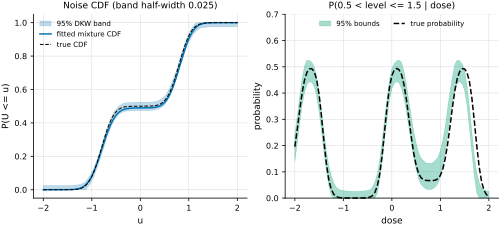

In [7]:
def true_noise_cdf(t: torch.Tensor) -> torch.Tensor:
    return 0.5 * torch.special.ndtr((t + 0.8) / 0.2) + 0.5 * torch.special.ndtr((t - 0.8) / 0.2)


t = torch.linspace(-2, 2, 400)
with torch.no_grad():
    band_lo, band_hi = band.noise_cdf_bounds(t.to(device))
    fitted_cdf = noise.cdf(t.unsqueeze(-1).to(device)).reshape(-1)
    doses = torch.linspace(-2, 2, 81).unsqueeze(-1)
    loc = mixture.mechanisms["level"].location(doses.to(device))
    p_lo, p_hi = band.interval_probability_bounds(torch.tensor(0.5).to(device),
                                                  torch.tensor(1.5).to(device), loc)
true_p = true_noise_cdf(1.5 - torch.sin(2 * doses)) - true_noise_cdf(0.5 - torch.sin(2 * doses))

fig, (ax_c, ax_p) = plt.subplots(1, 2, figsize=(DOUBLE, 3.2))
ax_c.fill_between(to_numpy(t), to_numpy(band_lo), to_numpy(band_hi), color=BLUE, alpha=0.25,
                  label="95% DKW band")
ax_c.plot(to_numpy(t), to_numpy(fitted_cdf), color=BLUE, lw=1.5, label="fitted mixture CDF")
ax_c.plot(to_numpy(t), to_numpy(true_noise_cdf(t)), color=INK, lw=1, ls="--", label="true CDF")
ax_c.set(xlabel="u", ylabel="P(U <= u)", title=f"Noise CDF (band half-width {band.epsilon:.3f})")
ax_c.legend(frameon=False, fontsize=7)
ax_p.fill_between(to_numpy(doses).reshape(-1), to_numpy(p_lo).reshape(-1), to_numpy(p_hi).reshape(-1),
                  color=AQUA, alpha=0.35, label="95% bounds")
ax_p.plot(to_numpy(doses), to_numpy(true_p), color=INK, lw=1.5, ls="--", label="true probability")
ax_p.set(xlabel="dose", ylabel="probability", title="P(0.5 < level <= 1.5 | dose)")
ax_p.set_ylim(0, 0.7)
ax_p.legend(frameon=False, fontsize=7, loc="upper center", ncol=2)
save(fig, "11_fig2")      # vector PDF + 300-dpi PNG in examples/figures/
plt.show()

**Figure.** Left: CDF of the noise `U`, fitted mixture and truth (dashed), with the 95% DKW band built on held-out residuals. Right: `P(0.5 < level <= 1.5 | dose)` with the 95% bounds that the band implies, and the truth (dashed).

## 4. Counterfactuals

These three patients got their observed dose.  What level would each have had
with dose 0.7?  Abduction recovers each patient's noise exactly
(`u = level - g(dose)`); the action sets the dose; the prediction is
`g(0.7) + u`.

In [8]:
patients = {k: v[:3] for k, v in held_out.items()}
world = mixture.counterfactual_sample(patients, do={"dose": 0.7})
print("counterfactual level under do(dose = 0.7):")
for i in range(3):
    print(f"  patient {i}: dose {patients['dose'][i, 0]:+.2f}, level {patients['level'][i, 0]:+.2f}"
          f"  ->  {world['level'][0, i, 0]:+.2f}")
print("(answers under the additive-noise model: the data identify only P(level | dose))")

counterfactual level under do(dose = 0.7):
  patient 0: dose +2.94, level -1.13  ->  +0.20
  patient 1: dose +1.00, level +1.65  ->  +1.75
  patient 2: dose +0.47, level +1.90  ->  +2.06
(answers under the additive-noise model: the data identify only P(level | dose))


Left: the abduction round trip.  Recover the noise of 500 held-out patients,
put it back through the structural equation at the observed dose, and compare
with the observed level: the points lie on the diagonal.  Right: eight
patients moved to dose 0.7.  Each keeps its own noise, so it keeps its distance
from the fitted location curve.

round trip: largest |rebuilt - observed| = 6.0e-08


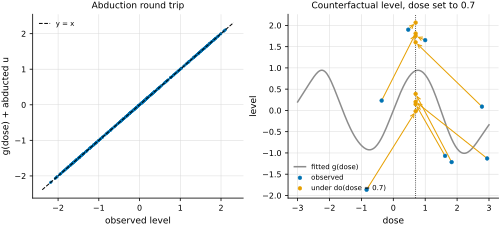

In [9]:
with torch.no_grad():
    obs_dose = held_out["dose"][:500].to(device)
    obs_level = held_out["level"][:500].to(device)
    u_hat = level_mech.abduct(obs_level, obs_dose)[0]
    rebuilt = level_mech.structural(obs_dose, u_hat)
print("round trip: largest |rebuilt - observed| =", f"{float((rebuilt - obs_level).abs().max()):.1e}")

few = {k: v[:8] for k, v in held_out.items()}
cf = mixture.counterfactual_sample(few, do={"dose": 0.7})["level"][0]

fig, (ax_r, ax_cf) = plt.subplots(1, 2, figsize=(DOUBLE, 3.2))
ax_r.scatter(to_numpy(obs_level), to_numpy(rebuilt), s=5, color=BLUE)
lims = (float(obs_level.min()) - 0.2, float(obs_level.max()) + 0.2)
ax_r.plot(lims, lims, color=INK, lw=1, ls="--", label="y = x")
ax_r.set(xlabel="observed level", ylabel="g(dose) + abducted u", title="Abduction round trip")
ax_r.legend(frameon=False, fontsize=7)
ax_cf.plot(to_numpy(grid), to_numpy(fitted_g), color=GREY, lw=1.5, label="fitted g(dose)")
ax_cf.axvline(0.7, color=INK, lw=0.8, ls=":")
for i in range(8):
    x0, y0, y1 = float(few["dose"][i, 0]), float(few["level"][i, 0]), float(cf[i, 0])
    ax_cf.annotate("", xy=(0.7, y1), xytext=(x0, y0),
                   arrowprops=dict(arrowstyle="->", color=ORANGE, lw=1))
ax_cf.scatter(to_numpy(few["dose"]), to_numpy(few["level"]), s=14, color=BLUE, zorder=3,
              label="observed")
ax_cf.scatter([0.7] * 8, to_numpy(cf), s=14, color=ORANGE, zorder=3, label="under do(dose = 0.7)")
ax_cf.set(xlabel="dose", ylabel="level", title="Counterfactual level, dose set to 0.7")
ax_cf.legend(frameon=False, fontsize=7, loc="lower left")
save(fig, "11_fig3")      # vector PDF + 300-dpi PNG in examples/figures/
plt.show()